# 02. Exploratory Data Analysis (EDA)
**UPI Fraud Detection and Risk Analytics**

### Objectives:
1. Analyze class balance of `Fraud_Label`.
2. Explore continuous distributions (`Amount`, `Processing_Time_sec`, `Bank_Response_Time_ms`) and compare normal vs fraudulent transactions.
3. Investigate categorical feature patterns (`UPI_App`, `Transaction_Type`, `Payment_Method`, `Sender_Bank`, `Receiver_Bank`).
4. Perform spatial & temporal breakdown (State, City, Month, Day of Week, Weekend vs Weekday).
5. Identify correlation structures and potential fraud indicators.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting
sns.set_style('whitegrid')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
%matplotlib inline


## 1. Load Processed Dataset

In [2]:
data_path = r"C:\UPI Data\UPI_Transactions_Cleaned.csv"
if not os.path.exists(data_path):
    data_path = r"C:\UPI Data\UPI_Transactions_Cleaned.csv"

df = pd.read_csv(data_path)
print(f'Dataset Loaded Successfully: {df.shape[0]} rows, {df.shape[1]} columns')
df.head()


Dataset Loaded Successfully: 10000 rows, 24 columns


,Transaction_ID,Transaction_Date,Customer_ID,City,State,Sender_Bank,Receiver_Bank,UPI_App,Transaction_Type,Payment_Method,Amount,Transaction_Status,Failure_Reason,Processing_Time_sec,Bank_Response_Time_ms,Fraud_Label,Year,Month,Month_Name,Day,Day_of_Week,Day_of_Week_Num,Is_Weekend,Quarter
0,TXN100000,2025-11-24,CUST09196,Bengaluru,Karnataka,SBI,Kotak Mahindra Bank,PhonePe,Online Purchase,Mobile Number,2014.53,Success,Not Applicable,4.83,801,0,2025,11,Nov,24,Monday,0,0,4
1,TXN100001,2025-04-23,CUST01520,Ahmedabad,Gujarat,Yes Bank,Kotak Mahindra Bank,BHIM,P2P,UPI ID,1359.97,Success,Not Applicable,1.58,751,0,2025,4,Apr,23,Wednesday,2,0,2
2,TXN100002,2025-06-26,CUST09460,Lucknow,Uttar Pradesh,Kotak Mahindra Bank,SBI,PhonePe,P2P,UPI,8199.06,Success,Not Applicable,3.03,816,0,2025,6,Jun,26,Thursday,3,0,2
3,TXN100003,2025-12-05,CUST05821,Mumbai,Maharashtra,Kotak Mahindra Bank,HDFC Bank,PhonePe,Bill Payment,UPI,2240.06,Success,Not Applicable,3.58,345,0,2025,12,Dec,5,Friday,4,0,4
4,TXN100004,2025-11-08,CUST00526,Kochi,Kerala,ICICI Bank,Union Bank,Paytm,Recharge,UPI ID,320.36,Success,Not Applicable,4.48,888,0,2025,11,Nov,8,Saturday,5,1,4


## 2. Target Variable Analysis (`Fraud_Label`)

Non-Fraudulent Transactions (0): 9901 (99.01%)
Fraudulent Transactions (1):     99 (0.99%)


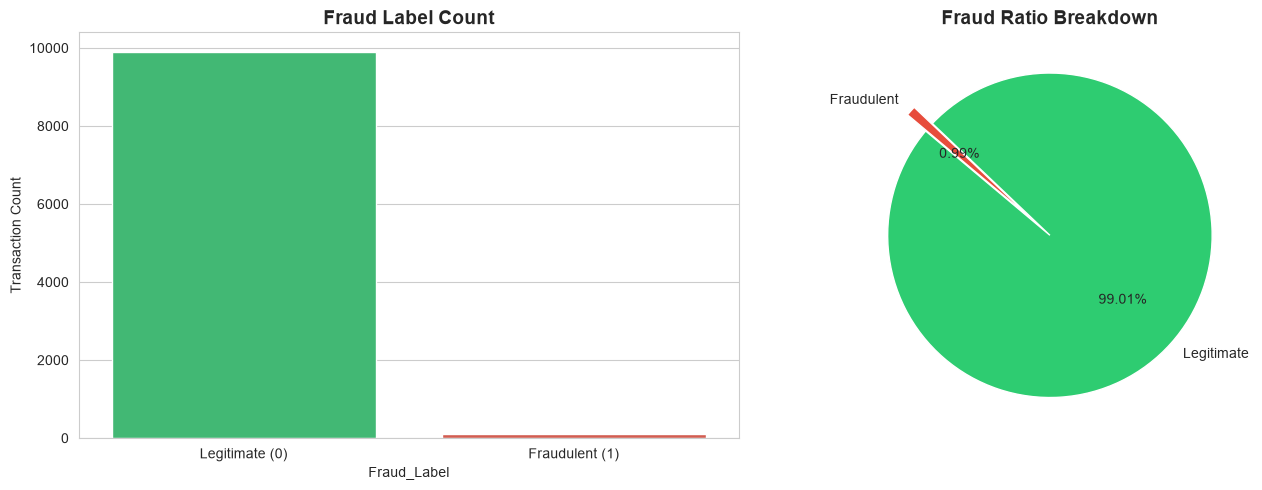

In [4]:

fraud_counts = df['Fraud_Label'].value_counts()
fraud_pct = df['Fraud_Label'].value_counts(normalize=True) * 100

print(f'Non-Fraudulent Transactions (0): {fraud_counts[0]} ({fraud_pct[0]:.2f}%)')
print(f'Fraudulent Transactions (1):     {fraud_counts[1]} ({fraud_pct[1]:.2f}%)')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = ['#2ecc71', '#e74c3c']

# Bar chart
sns.barplot(
    x=fraud_counts.index,
    y=fraud_counts.values,
    hue=fraud_counts.index,
    palette=colors,
    legend=False,
    ax=axes[0]
)

axes[0].set_title('Fraud Label Count', fontsize=14, fontweight='bold')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Legitimate (0)', 'Fraudulent (1)'])
axes[0].set_ylabel('Transaction Count')

# Pie chart
axes[1].pie(
    fraud_counts,
    labels=['Legitimate', 'Fraudulent'],
    autopct='%1.2f%%',
    colors=colors,
    startangle=140,
    explode=(0, 0.15)
)

axes[1].set_title('Fraud Ratio Breakdown', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()



## 3. Continuous Numerical Feature Analysis

In [5]:
num_cols = ['Amount', 'Processing_Time_sec', 'Bank_Response_Time_ms']

print('Summary Statistics by Fraud Status:')
display(df.groupby('Fraud_Label')[num_cols].describe().T)


Summary Statistics by Fraud Status:


Fraud_Label                             0             1
Amount                count   9901.000000     99.000000
                      mean    1340.727008   1177.882828
                      std     1840.886520   1373.198808
                      min       19.890000     31.910000
                      25%      413.940000    436.375000
                      50%      807.480000    751.720000
                      75%     1598.160000   1514.980000
                      max    63776.840000  10897.670000
Processing_Time_sec   count   9901.000000     99.000000
                      mean       3.981593      4.420909
                      std        2.715053      3.703538
                      min        0.300000      0.300000
                      25%        2.020000      2.030000
                      50%        3.380000      3.530000
                      75%        5.290000      5.745000
                      max       30.000000     24.890000
Bank_Response_Time_ms count   9901.000000     99.000000
                      mean     652.156449    692.111111
                      std      246.366659    243.915462
                      min       80.000000     80.000000
                      25%      482.000000    549.000000
                      50%      653.000000    708.000000
                      75%      818.000000    855.000000
                      max     1620.000000   1317.000000

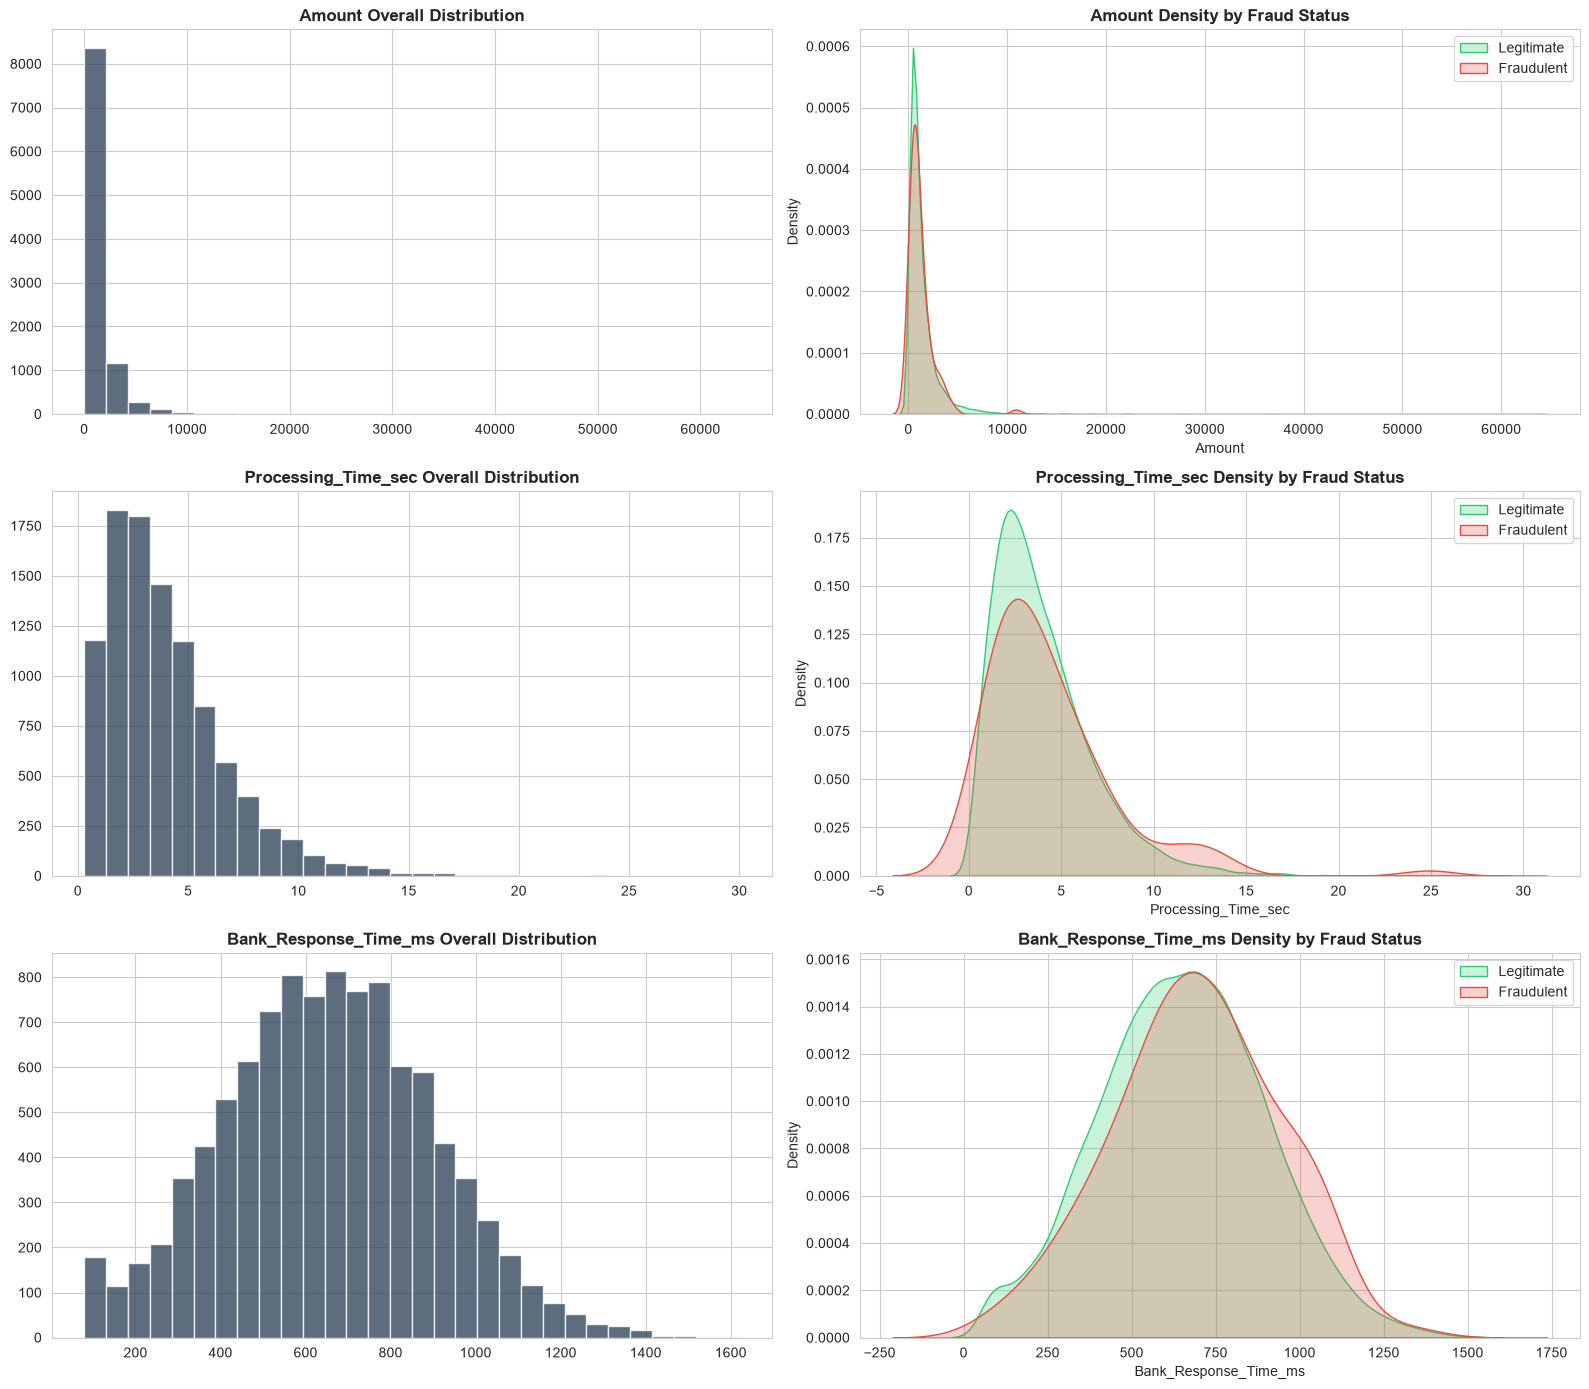

In [11]:

fig, axes = plt.subplots(3, 2, figsize=(16, 14))

for i, col in enumerate(num_cols):

    # Overall Distribution
    axes[i, 0].hist(
        df[col],
        bins=30,
        color='#34495e',
        edgecolor='white',
        alpha=0.8
    )
    axes[i, 0].set_title(
        f'{col} Overall Distribution',
        fontsize=12,
        fontweight='bold'
    )

    # Distribution split by Fraud_Label
    for label, color, name in [
        (0, '#2ecc71', 'Legitimate'),
        (1, '#e74c3c', 'Fraudulent')
    ]:
        sns.kdeplot(
            df[df['Fraud_Label'] == label][col],
            ax=axes[i, 1],
            color=color,
            label=name,
            fill=True
        )

    axes[i, 1].legend()
    axes[i, 1].set_title(
        f'{col} Density by Fraud Status',
        fontsize=12,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()



## 4. Categorical Feature Distributions & Fraud Rates

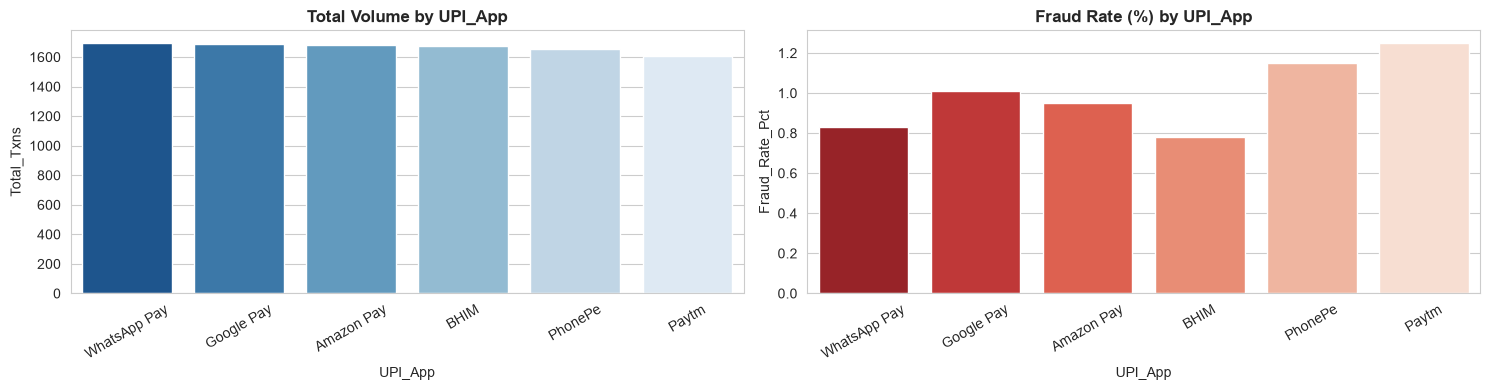

--- Summary for UPI_App ---
     UPI_App  Total_Txns  Fraud_Txns  Fraud_Rate  Fraud_Rate_Pct
WhatsApp Pay        1695          14    0.008260            0.83
  Google Pay        1686          17    0.010083            1.01
  Amazon Pay        1682          16    0.009512            0.95
        BHIM        1675          13    0.007761            0.78
     PhonePe        1657          19    0.011467            1.15
       Paytm        1605          20    0.012461            1.25




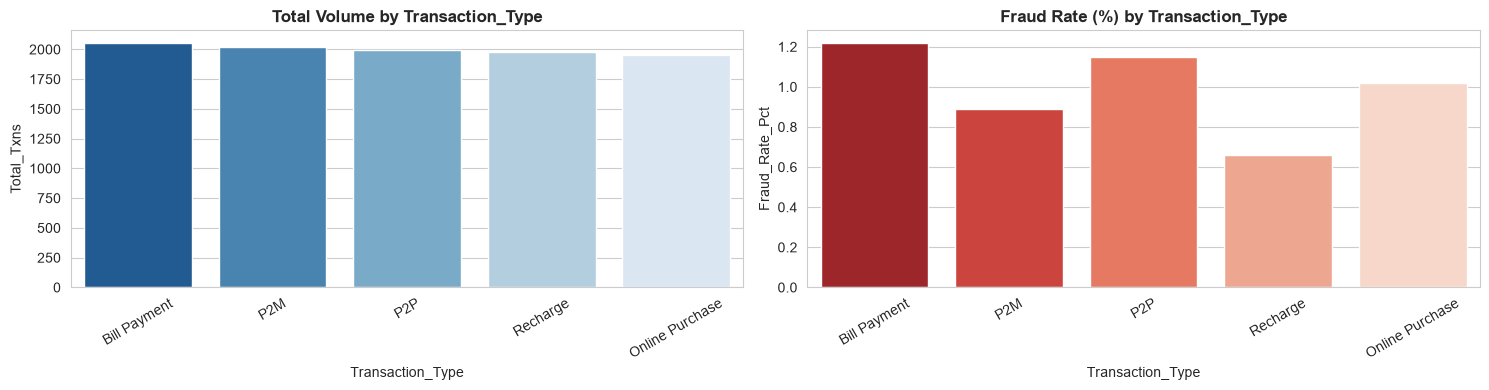

--- Summary for Transaction_Type ---
Transaction_Type  Total_Txns  Fraud_Txns  Fraud_Rate  Fraud_Rate_Pct
    Bill Payment        2056          25    0.012160            1.22
             P2M        2017          18    0.008924            0.89
             P2P        1995          23    0.011529            1.15
        Recharge        1977          13    0.006576            0.66
 Online Purchase        1955          20    0.010230            1.02




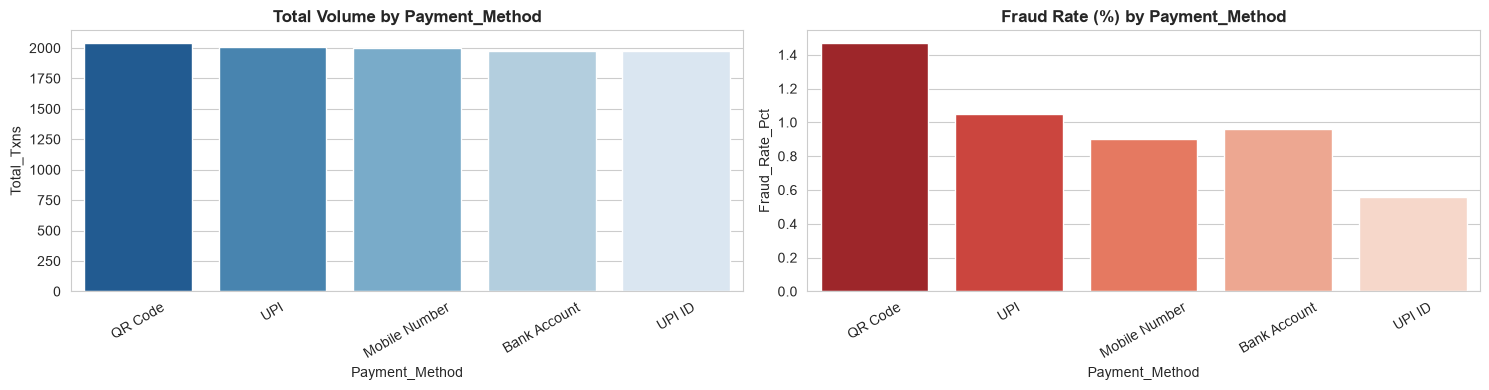

--- Summary for Payment_Method ---
Payment_Method  Total_Txns  Fraud_Txns  Fraud_Rate  Fraud_Rate_Pct
       QR Code        2042          30    0.014691            1.47
           UPI        2005          21    0.010474            1.05
 Mobile Number        2002          18    0.008991            0.90
  Bank Account        1978          19    0.009606            0.96
        UPI ID        1973          11    0.005575            0.56




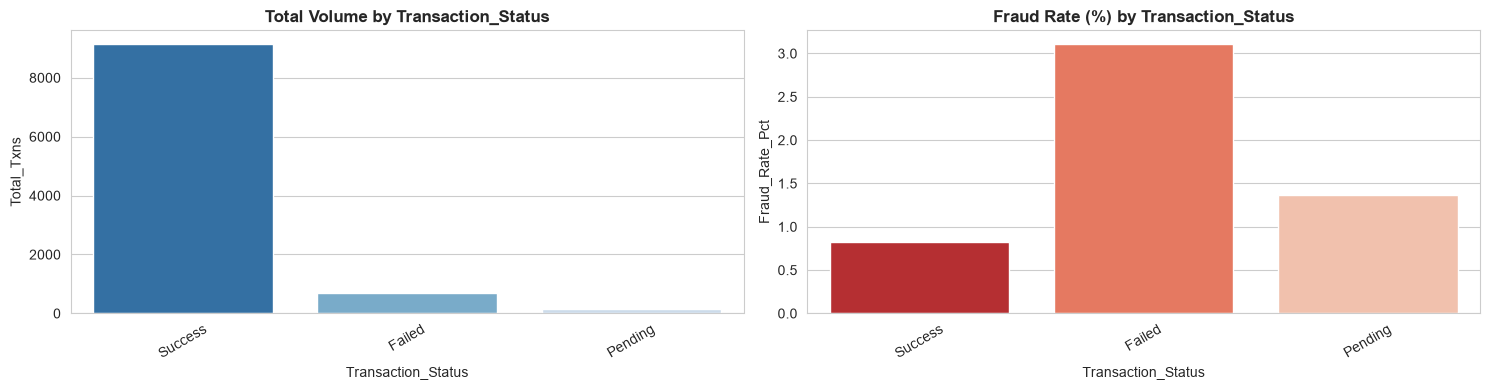

--- Summary for Transaction_Status ---
Transaction_Status  Total_Txns  Fraud_Txns  Fraud_Rate  Fraud_Rate_Pct
           Success        9147          75    0.008199            0.82
            Failed         707          22    0.031117            3.11
           Pending         146           2    0.013699            1.37




In [12]:

cat_cols = ['UPI_App', 'Transaction_Type', 'Payment_Method', 'Transaction_Status']

for col in cat_cols:
    grouped = df.groupby(col).agg(
        Total_Txns=('Fraud_Label', 'count'),
        Fraud_Txns=('Fraud_Label', 'sum'),
        Fraud_Rate=('Fraud_Label', 'mean')
    ).reset_index()
    grouped['Fraud_Rate_Pct'] = (grouped['Fraud_Rate'] * 100).round(2)
    grouped = grouped.sort_values(by='Total_Txns', ascending=False)

    fig, axes = plt.subplots(1, 2, figsize=(15, 4))
    sns.barplot(data=grouped, x=col, y='Total_Txns', hue=col, palette='Blues_r', legend=False, ax=axes[0])
    axes[0].set_title(f'Total Volume by {col}', fontsize=12, fontweight='bold')
    axes[0].tick_params(axis='x', rotation=30)

    sns.barplot(data=grouped, x=col, y='Fraud_Rate_Pct', hue=col, palette='Reds_r', legend=False, ax=axes[1])
    axes[1].set_title(f'Fraud Rate (%) by {col}', fontsize=12, fontweight='bold')
    axes[1].tick_params(axis='x', rotation=30)

    plt.tight_layout()
    plt.show()
    print(f'--- Summary for {col} ---')
    print(grouped.to_string(index=False))
    print('\n' + '=' * 60 + '\n')


## 5. Bank Interaction Analysis

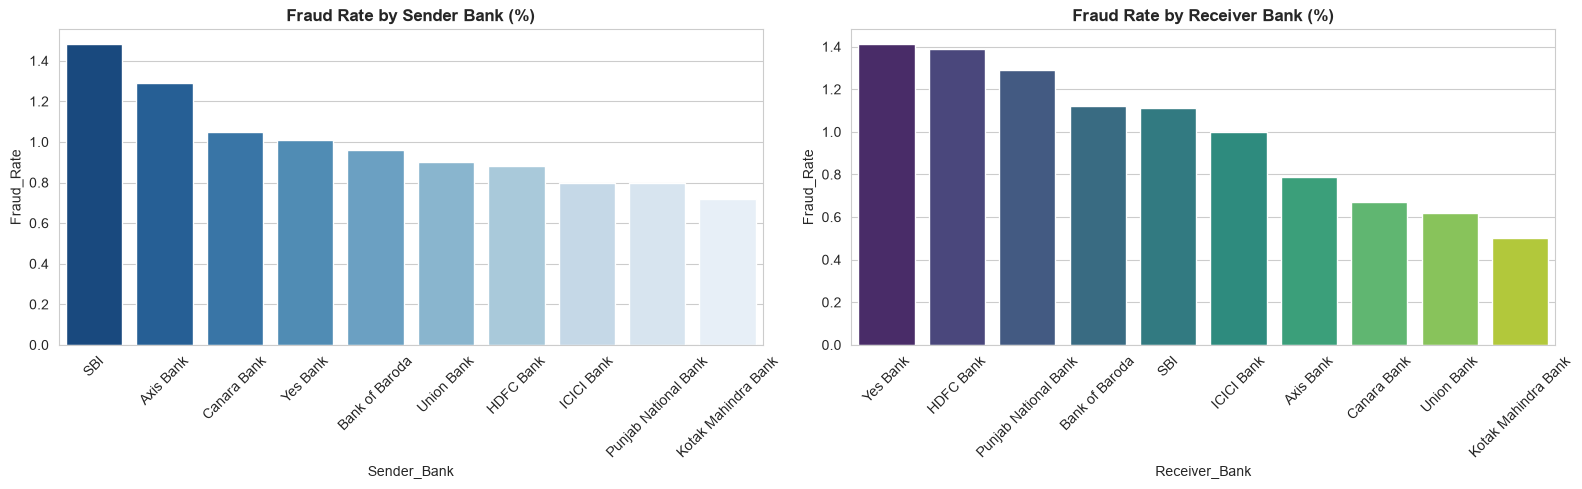

In [13]:
sender_df = df.groupby('Sender_Bank').agg(
    Volume=('Fraud_Label', 'count'),
    Fraud_Count=('Fraud_Label', 'sum'),
    Fraud_Rate_Mean=('Fraud_Label', 'mean')
)
sender_df['Fraud_Rate'] = (sender_df['Fraud_Rate_Mean'] * 100).round(2)
sender_df = sender_df.sort_values(by='Fraud_Rate', ascending=False)

receiver_df = df.groupby('Receiver_Bank').agg(
    Volume=('Fraud_Label', 'count'),
    Fraud_Count=('Fraud_Label', 'sum'),
    Fraud_Rate_Mean=('Fraud_Label', 'mean')
)
receiver_df['Fraud_Rate'] = (receiver_df['Fraud_Rate_Mean'] * 100).round(2)
receiver_df = receiver_df.sort_values(by='Fraud_Rate', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(x=sender_df.index, y=sender_df['Fraud_Rate'], hue=sender_df.index, palette='Blues_r', legend=False, ax=axes[0])
axes[0].set_title('Fraud Rate by Sender Bank (%)', fontsize=12, fontweight='bold')
axes[0].tick_params(axis='x', rotation=45)

sns.barplot(x=receiver_df.index, y=receiver_df['Fraud_Rate'], hue=receiver_df.index, palette='viridis', legend=False, ax=axes[1])
axes[1].set_title('Fraud Rate by Receiver Bank (%)', fontsize=12, fontweight='bold')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()



## 6. Spatial & Temporal Patterns

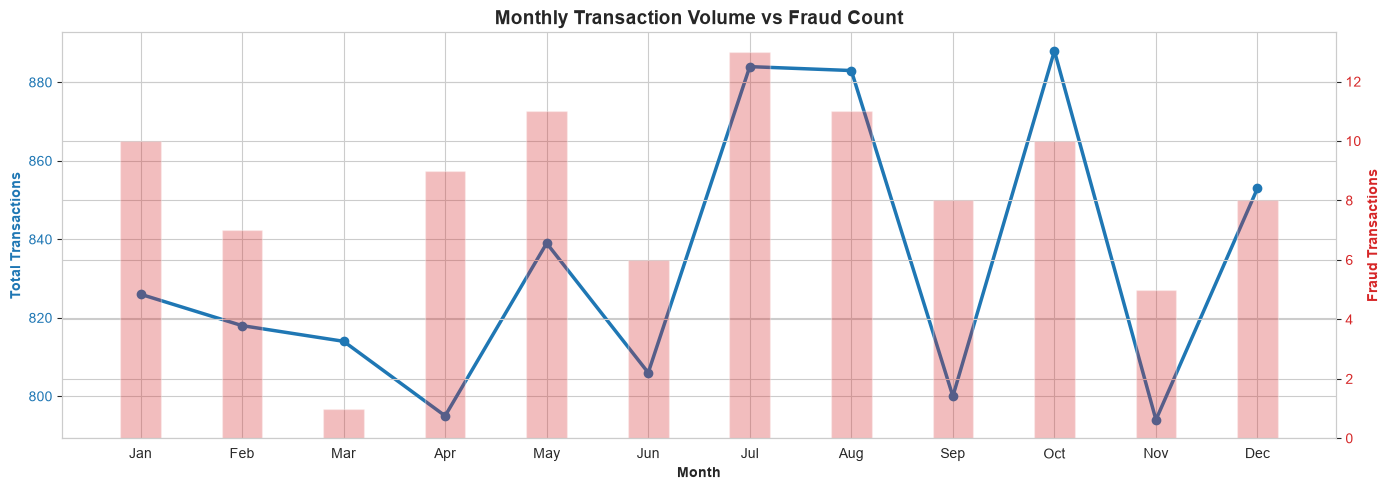

In [9]:
monthly = df.groupby('Month_Name').agg(
    Txn_Volume=('Fraud_Label', 'count'),
    Fraud_Count=('Fraud_Label', 'sum')
).reindex(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])

fig, ax1 = plt.subplots(figsize=(14, 5))
color = 'tab:blue'
ax1.set_xlabel('Month', fontweight='bold')
ax1.set_ylabel('Total Transactions', color=color, fontweight='bold')
ax1.plot(monthly.index, monthly['Txn_Volume'], color=color, marker='o', linewidth=2.5)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()  
color = 'tab:red'
ax2.set_ylabel('Fraud Transactions', color=color, fontweight='bold')
ax2.bar(monthly.index, monthly['Fraud_Count'], color=color, alpha=0.3, width=0.4)
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Monthly Transaction Volume vs Fraud Count', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## 7. Correlation Matrix

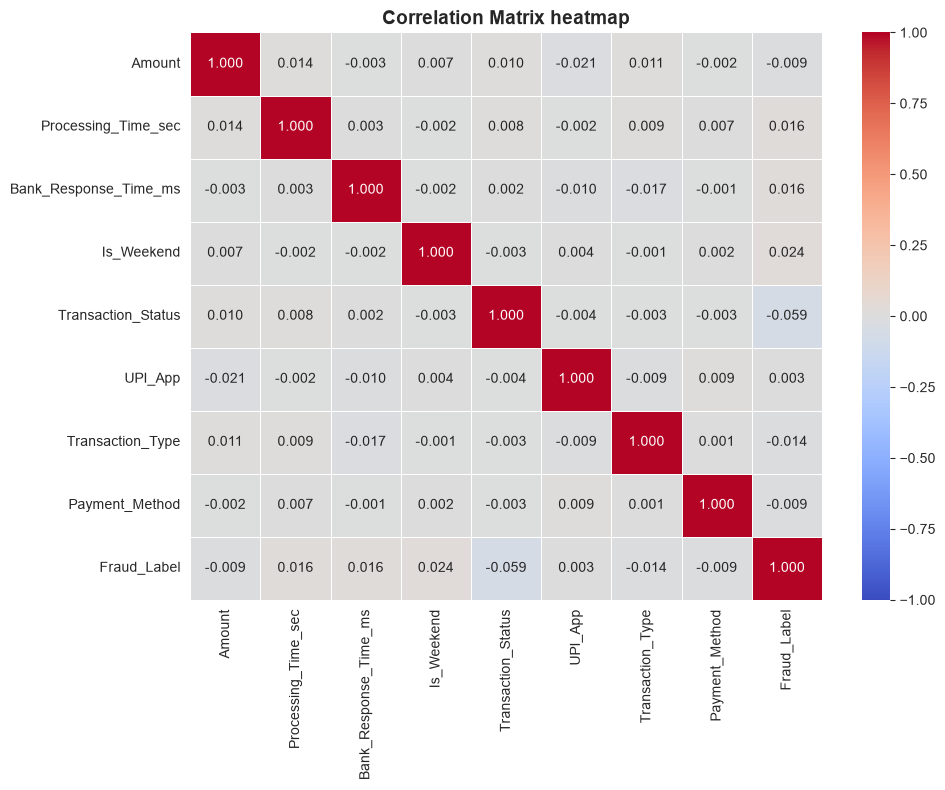

In [10]:
corr_df = df.copy()
# Encode select categorical variables for correlation visualization
for col in ['Transaction_Status', 'UPI_App', 'Transaction_Type', 'Payment_Method']:
    corr_df[col] = corr_df[col].astype('category').cat.codes

corr_cols = ['Amount', 'Processing_Time_sec', 'Bank_Response_Time_ms', 'Is_Weekend', 'Transaction_Status', 'UPI_App', 'Transaction_Type', 'Payment_Method', 'Fraud_Label']
corr_matrix = corr_df[corr_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Matrix heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()
